# Figure 4 — neurobiology of the developmental rate of INT change (HCP-D)

At each age, the regional pattern of the fitted rate of change (from fig3's GAMs) is correlated with
reference brain maps — gene-expression components from the Allen Human Brain Atlas and HCP-D's own
group-mean T1w/T2w myelin map — against BrainSMASH surrogates of each reference map

## Configuration and the fig3 export

In [1]:
import os
import re
import warnings

warnings.simplefilter('ignore', UserWarning)
warnings.simplefilter('ignore', FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from src.notebook import load_notebook_data
from src.timescales import rest_window_match_for
from src.gams import (grid_derivatives, deriv_map_spatial_null_p,
                      SIGNAL_TYPES, signal_labels, signal_units, gam_variant_tags,
                      gam_cache_path)
from src.nulls import (null_basis, generate_surrogates, corr_with_null,
                       require_full_parcellation)
from src.plotting import figure_scratch_dir, setup_notebook_style
from snaplab_tools.plotting.utils import save_panel
from snaplab_tools.stats import pca_with_nan_handling
from snaplab_tools.plotting.plotting import plot_correlation, plot_brain_surface_data_single
from snaplab_tools.plotting.utils import get_snap_colors

setup_notebook_style()

%matplotlib inline

In [2]:
dataset        = 'HCP-D'
n_regions      = 400
output_type    = 'timescale_auc_zero_crossing_bp-0.01-0.08hz'   # as in fig3's config cell

# ── Brain-gene panel ────────────────────────────────────────────────────────────────────────────
# gene_panel picks the brain-gene list the gene PCA is fit on (data/supporting_data/<tag>_brain_genes.txt:
# 'gao' ~2k genes, 'dear' ~8k).
gene_panel = 'gao'          # 'gao' or 'dear'
gene_tag   = f'_{gene_panel}'

notebook_data        = load_notebook_data(dataset=dataset, output_type=output_type, use_resids=True,
                                          load_myelin=True, n_regions=n_regions,
                                          gene_panel=gene_panel)
timescales_processor = notebook_data['timescales_processor']

fig_dir = figure_scratch_dir(dataset)

Loading data for notebooks...
Initialized DataLoader for dataset: HCP-D
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D/processed
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       652 subjects

	Initialized Timescales for dataset: HCP-D
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
	Brain-gene panel 'gao': 2031/2429 symbols present in the expression matrix -> PCA input (400, 2031).
Loaded 2760 scans from scan_registry_HCP-D.csv


Loading metric_tsnr: 100%|██████████| 2760/2760 [00:00<00:00, 7071.29it/s]
Loading timescale_auc_zero_crossing_bp-0.01-0.08hz: 100%|██████████| 2760/2760 [00:00<00:00, 8163.26it/s]
Loading timescale_auc_zero_crossing_bp-0.01-0.08hz_resids: 100%|██████████| 2760/2760 [00:00<00:00, 8167.89it/s]


Number of subjects: 552
Myelin: 552/552 subjects have a map


In [3]:
# The GAM export fig3 writes, which every cell below reads (fig4 fits nothing).
task_scan = 'tfMRICARITPA'
# task_scan = 'tfMRIEMOTIONPA'
# task_scan = 'tfMRIGUESSINGPA'

# These must match fig3's GAM config, because they name the cache file and are cross-checked against the
# values recorded in it.
fit_recipe = 'gcv'  # 'historical' -> n_splines=4, lam=0.1 fixed; 'gcv' -> n_splines=5, GCV lam
absolute   = True   # deflection definition: True -> |task - rest|, False -> signed (task - rest)
demean     = True   # each series centred on its own mean before fitting
REST_LENGTH = 'matched'  # rest INTs: 'full' runs or 'matched' windows (src.timescales.REST_WINDOW_MATCH)
# The windows follow task_scan (restlen-CARIT for tfMRICARITPA), resolved exactly as fig3 does.
REST_MATCH  = rest_window_match_for(dataset, task_scan) if REST_LENGTH == 'matched' else None

_tags        = gam_variant_tags(fit_recipe, absolute, demean, rest_length=REST_LENGTH,
                                rest_match=REST_MATCH)
n_splines    = _tags['n_splines']
recipe_tag   = _tags['recipe_tag']
absolute_tag = _tags['absolute_tag']
demean_tag   = _tags['demean_tag']

# Which INT signal this run of the figure characterises. fig3 exports all three, so switching here
# is enough -- the neurobiological coupling, stage maps, S-A statistics and PC characterisation
# below all follow signal_type, and every saved panel carries it in its filename.
signal_type = 'deflection'          # 'rest', 'task', or 'deflection'

# STAGE_BOUNDARY is 'deflection' (the shared boundary fig3 draws) or 'signal' (detected on signal_type's own
# fit).
STAGE_BOUNDARY = 'deflection'

SIGNAL_LABELS = signal_labels(absolute)   # both dicts are shared with fig3, so the two figures
SIGNAL_UNITS  = signal_units(absolute)    # cannot label the same signal differently
if signal_type not in SIGNAL_TYPES:
    raise ValueError(f'signal_type must be one of {list(SIGNAL_TYPES)}; got {signal_type!r}')
if STAGE_BOUNDARY not in ('deflection', 'signal'):
    raise ValueError(f"STAGE_BOUNDARY must be 'deflection' or 'signal'; got {STAGE_BOUNDARY!r}")
SIGNAL_LABEL = SIGNAL_LABELS[signal_type]
SIGNAL_UNIT  = SIGNAL_UNITS[signal_type]
# variant_tag means the same as in fig3, so panel names match across the two notebooks.
variant_tag  = _tags['variant_tag']

gam_file = gam_cache_path(os.path.join(timescales_processor.output_dir, 'results', dataset, 'gam'),
                          dataset, n_regions, task_scan, _tags)
if not os.path.exists(gam_file):
    raise FileNotFoundError(
        f'GAM export not found:\n  {gam_file}\n'
        'Run timescales_analysis_fig3.ipynb (through its GAM + bootstrap cell) first to generate it.')
_d = np.load(gam_file, allow_pickle=True).item()

# Exactly the keys Figure 4 consumes -- an export missing any of them predates this notebook.
_required = ['age_grid', 'sa_axis', 'df_behavior', 'n_splines', 'boot_seed', 'inflection_age',
             'rest_reg', f'{signal_type}_pred', f'{signal_type}_reg', f'{signal_type}_lams',
             f'{signal_type}_inflection_age']
_missing  = [k for k in _required if k not in _d]
if _missing:
    raise KeyError(f'GAM export {os.path.basename(gam_file)} is missing keys {_missing}; re-run '
                   "fig3's GAM + bootstrap cell with FORCE_RERUN = True to regenerate it.")

age_grid    = _d['age_grid']
sa_axis     = _d['sa_axis']           # full-parcellation axis (== fig3's sa_axis_reg when
                                      # unmasked, which the guard below requires)
df_behavior = _d['df_behavior']
rest_reg    = _d['rest_reg']          # (n_sub, n_regions) resting INT; part of the export
                                      # contract (fig3's nuisance term), unused here

# Per-signal inputs, of which only sig_pred is plotted (sig_reg and sig_lams are checked as part of the export
# contract).
sig_pred = _d[f'{signal_type}_pred']  # (n_regions, n_grid) fitted smooths
sig_reg  = _d[f'{signal_type}_reg']   # (n_sub, n_regions) subject data behind those smooths
sig_lams = _d[f'{signal_type}_lams']  # (n_regions,) frozen per-region smoothing
inflection_age = float(_d['inflection_age'] if STAGE_BOUNDARY == 'deflection'
                       else _d[f'{signal_type}_inflection_age'])

# The filename encodes most of these, but check the values recorded INSIDE the export too -- a
# hand-renamed or stale cache would otherwise be silently mislabelled in every panel below.
for _name, _want in [('absolute', bool(absolute)), ('demean', bool(demean)),
                     ('fit_recipe', fit_recipe), ('n_splines', n_splines),
                     ('task_scan', task_scan), ('rest_length', REST_LENGTH),
                     ('rest_match', REST_MATCH)]:
    if _name not in _d:
        continue                                     # older export; the filename still pins it
    _got = bool(_d[_name]) if isinstance(_want, bool) else _d[_name]
    if _got != _want:
        raise ValueError(f'{os.path.basename(gam_file)} was built with {_name}={_got!r}, but this '
                         f'cell asks for {_name}={_want!r}. Fix the flag or regenerate the cache.')

# Refuse a tSNR-masked export, since the surface panels and nulls need the full parcellation.
if _d.get('region_mask_applied', False):
    raise ValueError(f'{os.path.basename(gam_file)} was built with fig3\'s apply_tsnr_mask on. '
                     'Re-run fig3 with apply_tsnr_mask = False.')
require_full_parcellation(sig_pred.shape[0], n_regions, os.path.basename(gam_file),
                          'Re-run fig3 with apply_tsnr_mask = False.')

print(f'Loaded GAM export <- {os.path.basename(gam_file)} '
      f'(absolute={absolute}, demean={demean}, rest_length={REST_LENGTH}, rest_match={REST_MATCH})')
print(f'  signal_type={signal_type!r} ({SIGNAL_LABEL}); sig_pred {sig_pred.shape} '
      f'on age_grid {age_grid.shape}')
print(f'  stage boundary {inflection_age:.2f} yr (from {STAGE_BOUNDARY}) | this signal\'s own '
      f'{_d[f"{signal_type}_inflection_age"]:.2f} yr | deflection {_d["inflection_age"]:.2f} yr')
print(f'  sig_reg {sig_reg.shape} | rest_reg {rest_reg.shape} | df_behavior {df_behavior.shape}')

Loaded GAM export <- HCP-D_400_tfMRICARITPA_ns5-gcv_abs_demean_restlen-CARIT_regional_gam_results.npy (absolute=True, demean=True, rest_length=matched, rest_match=CARIT)
  signal_type='deflection' (INT Deflections (abs.)); sig_pred (400, 200) on age_grid (200,)
  stage boundary 15.03 yr (from deflection) | this signal's own 15.03 yr | deflection 15.03 yr
  sig_reg (552, 400) | rest_reg (552, 400) | df_behavior (552, 45)


## Neurobiological coupling to the developmental rate

For whichever signal `signal_type` selects (rest INTs, task INTs, or task-vs-rest deflections), at each
age the regional pattern of the GAM's temporal derivative is correlated against a set of reference
brain maps (genes, myelin), with significance from SA-preserving BrainSMASH surrogates of the
reference map. The per-stage net change on the S-A axis is a supplement of
`timescales_analysis_fig3.ipynb`.

In [4]:
# ── Column-family inclusion toggles ──────────────────────────────────────────────────────────────
# Set a flag False to drop that family: AHBA gene maps (INCLUDE_GENE_MAPS) or this dataset's own myelin map (INCLUDE_OWN_MYELIN_MAP).
INCLUDE_GENE_MAPS      = True
INCLUDE_OWN_MYELIN_MAP = True

# ── Analysis hemisphere ─────────────────────────────────────────────────────────────────────────
# LEFT_HEMI_ONLY restricts the reference-map analyses (not fig3's INT maps) to the left hemisphere, where AHBA
# sampling is concentrated, with surrogates cached separately ('_L').
LEFT_HEMI_ONLY = False

# Number of gene-expression PCs fitted in this notebook.
N_PCS = 3

# PCA_FLIP_SIGN negates every component (scores and loadings together), which flips the sign of every reported
# correlation but not its magnitude or p.
PCA_FLIP_SIGN = False

# Number of BrainSMASH surrogates for every spatial null here, cached per map and count.
N_PERMS = 10000
# N_PERMS = 1000

# The geodesic distance matrix and surrogate cache that both compute cells use.
distance_matrix, hemi_labels, cache_dir = null_basis(timescales_processor, dataset, n_regions)
print(f'BrainSMASH basis: geodesic distances {distance_matrix.shape}, {N_PERMS} surrogates per map')
print(f'Surrogate cache: {cache_dir}')

# LEFT_HEMI_ONLY sets right-hemisphere parcels to NaN rather than subsetting, so every map stays full length.
hemi_mask = (np.asarray(hemi_labels) == 'L') if LEFT_HEMI_ONLY else np.ones(n_regions, dtype=bool)
hemi_tag  = '_L' if LEFT_HEMI_ONLY else ''

def restrict_hemi(vals):
    """NaN out parcels outside the analysis hemisphere. A no-op when LEFT_HEMI_ONLY is False."""
    out = np.asarray(vals, dtype=float).copy()
    out[~hemi_mask] = np.nan
    return out

print(f'Analysis hemisphere: {"LEFT only" if LEFT_HEMI_ONLY else "bilateral"} '
      f'({int(hemi_mask.sum())}/{n_regions} parcels). Applies to the reference-map analyses.')

BrainSMASH basis: geodesic distances (400, 400), 10000 surrogates per map
Surrogate cache: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales/results/HCP-D/brainsmash_nulls
Analysis hemisphere: bilateral (400/400 parcels). Applies to the reference-map analyses.


## Molecular maps: genes

`gene_curated` is the only control over which maps enter the figure. The cell prints the full
catalogue of names it accepts.


## Panel + analysis support

Helpers for this notebook, gathered so the cells below stay readable. Collapse it.

In [5]:
# ── Panel + analysis support ────────────────────────────────────────────────────────────────
# Notebook-specific helpers, resolving globals at call time (anything a second notebook needs belongs in src/).

# ── Helpers used by the cells below ──────────────────────────────────────────────────────────────
# save_panel (snaplab_tools.plotting.utils) writes every panel as PNG + SVG at 300 dpi with a tight
# bbox, the SVG staying text-editable thanks to svg.fonttype='none'.
def longest_sig_run(p, alpha):
    """Length (in age-grid points) of the longest run of consecutive p < alpha; 0 if none."""
    best = run = 0
    for hit in np.asarray(p) < alpha:
        run = run + 1 if hit else 0
        best = max(best, run)
    return best


def fit_family_pca(df, n_components, label, flip=False, row_mask=None):
    """Fit a family's PCA and keep everything needed to interpret and re-fit it.

    load_supporting_data returns the raw expression / receptor matrices only -- the components live
    here so that the fit, its interpretation and its bootstrap all sit in one place. Standardised
    and NaN-imputed, so scores come back for every parcel; parcels with no data at all are pure
    imputation and are masked out by the caller.

    Adds two things ``pca_with_nan_handling`` does not return: the feature names in loadings order
    (without which loadings cannot be mapped back to genes) and the input matrix (without which the
    stability bootstrap has nothing to re-fit).

    ``flip`` negates scores AND loadings together (see PCA_FLIP_SIGN). Both must move or the two
    stop describing the same component; ``input_data`` is deliberately left alone, since the data
    have no sign and the bootstrap re-fits from them and re-aligns to whichever reference it is
    given. Nothing else in the returned dict is sign-carrying for our purposes.

    ``row_mask`` (n_parcels,) restricts which parcels the component is FIT on -- this is how
    LEFT_HEMI_ONLY works. The fit must drop those rows rather than NaN them, because impute=True
    would otherwise fill them with column medians and let phantom parcels shape the components.
    Scores are scattered back to full parcel length with NaN outside the mask, so every consumer
    still sees an (n_regions,) map. ``input_data`` is the masked matrix (out-of-mask rows all-NaN,
    which is exactly what loading_pole_stability's all-NaN row drop expects, keeping the bootstrap
    on the same parcels as the fit); ``input_data_full`` keeps the unrestricted matrix for export.
    """
    X_full = np.asarray(df, dtype=float)
    mask   = np.ones(X_full.shape[0], dtype=bool) if row_mask is None else np.asarray(row_mask, dtype=bool)
    out = pca_with_nan_handling(X_full[mask], n_components=n_components, standardize=True,
                                impute=True)
    if flip:
        out['scores']   = -out['scores']
        out['loadings'] = -out['loadings']
    scores_full = np.full((X_full.shape[0], n_components), np.nan)
    scores_full[mask]     = out['scores']
    out['scores']         = scores_full
    out['row_mask']       = mask
    out['feature_names']  = list(df.columns)
    X_masked              = X_full.copy()
    X_masked[~mask]       = np.nan
    out['input_data']     = X_masked
    out['input_data_full'] = X_full
    print(f'{label} PCA: {X_full.shape[1]} features x {int(mask.sum())} parcels '
          f'({"LEFT hemisphere only" if not mask.all() else "bilateral"}) -> {n_components} '
          f'components ({", ".join(f"{v:.1%}" for v in out["explained_variance_ratio"])} variance)'
          + ('  [SIGN FLIPPED: every correlation below changes sign, magnitudes do not]'
             if flip else ''))
    return out


def loading_pole_stability(X, ref_loadings, n_boot, window, seed=0):
    """How reproducibly each feature re-enters each pole's top-``window`` under parcel resampling.

    The PCA is re-fit on bootstrap resamples of the parcels that carry data, and each re-fit's
    components are matched back to the reference fit by |correlation| of their loading vectors and
    then sign-aligned -- necessary because PCA is only defined up to sign, and components with
    similar explained variance can swap order between resamples.

    ``window`` is deliberately wider than the number of features plotted: it defines "belongs to this
    pole at all", so the eligible pool is larger than the panel and the top-N selection can be drawn
    from it. Stability is only comparable across runs that share the same ``window``.

    Returns (pos_freq, neg_freq), each (n_features, n_components) in [0, 1]: the fraction of re-fits
    in which the feature appeared in that component's ``window`` most positive / most negative
    loadings.
    """
    X    = np.asarray(X, dtype=float)
    rows = X[~np.isnan(X).all(axis=1)]                       # drop parcels with no data at all
    n_comp = ref_loadings.shape[1]
    pos, neg = (np.zeros(ref_loadings.shape) for _ in range(2))
    rng = np.random.default_rng(seed)
    for _ in range(n_boot):
        boot = pca_with_nan_handling(rows[rng.choice(len(rows), len(rows), replace=True)],
                                     n_components=n_comp, standardize=True, impute=True)['loadings']
        for k in range(n_comp):
            corr = [np.corrcoef(ref_loadings[:, k], boot[:, m])[0, 1] for m in range(n_comp)]
            j    = int(np.argmax(np.abs(corr)))
            w    = boot[:, j] * np.sign(corr[j])
            pos[np.argsort(w)[::-1][:window], k] += 1
            neg[np.argsort(w)[:window], k] += 1
    return pos / n_boot, neg / n_boot


def catalog_add(catalog, name, values, *aliases):
    """Register one map under its canonical name plus any alternative spellings.

    ``name`` becomes the DataFrame column -- and therefore both the trace label and the BrainSMASH
    null-cache filename stem -- so it must stay stable. Aliases exist only so the curated lists can
    be written in whichever form reads best.
    """
    entry = (name, np.asarray(values, dtype=float))
    for key in (name, *aliases):
        catalog[key] = entry


def select_maps(catalog, curated, family):
    """The maps named in ``curated``, in that order, as a (n_regions x n_maps) DataFrame.

    Unknown names raise with the catalogue listed, so a typo fails loudly instead of quietly
    shrinking the panel. A map named twice (directly and via an alias) is kept once.
    """
    unknown = [k for k in curated if k not in catalog]
    if unknown:
        raise KeyError(f'{family}: unknown map name(s) {unknown}.\nAvailable names:\n  '
                       + '\n  '.join(sorted({nm for nm, _ in catalog.values()})))
    out = {}
    for key in curated:
        name, values = catalog[key]
        out.setdefault(name, values)
    return pd.DataFrame(out)


# Gene maps exist only at Schaefer-400, and downstream cells skip any family whose DataFrame is None.
df_neuro_full = notebook_data['supporting_data']['df_neuro'].copy()

In [6]:
# ── Curated gene panels (AHBA symbols; all present in df_neuro as Gene_*) ────────────────────────
# Hypothesis-driven sets, kept as named vocabulary for gene_curated below.
genes_original = ['GRIN2B', 'GRIN2A', 'GABRA3', 'GABRA1', 'PVALB', 'PRR5', 'KCNA3', 'SCN1A']

genes_recurrent_excitation = [        # recurrent / glutamatergic synaptic strength
      'GRIN1', 'GRIN2A', 'GRIN2B',            # NMDA receptor subunits
      'GRIA1', 'GRIA2', 'GRIA3', 'GRIA4',     # AMPA receptor subunits
      'GRM5',                                 # metabotropic glutamate receptor 5
      'CAMK2A', 'CAMK2B',                     # postsynaptic Ca2+/calmodulin kinase
      'DLG4',                                 # PSD-95
      'SYNGAP1', 'SHANK3', 'HOMER1',          # postsynaptic scaffolding / signaling
]

genes_presynaptic_exocytosis = [      # presynaptic / calcium-regulated exocytosis
      'SYT1',                                 # synaptotagmin-1 (Ca2+ sensor)
      'STX1A', 'STXBP1', 'SNAP25', 'VAMP2',   # SNARE complex
      'RIMS1',                                # active-zone release machinery
      'CACNA1A', 'CACNA1B',                   # presynaptic Ca2+ channels (P/Q, N-type)
      'SV2A',                                 # synaptic vesicle glycoprotein 2A
      'SYN1', 'SYP',                          # synapsin-1, synaptophysin
      'CPLX1', 'CPLX2',                       # complexins
]

# ── Which gene maps go into the figure ──
# One list, in plotting order, mixing freely:
#   AHBA gene symbols  'GRIN2B'        (also accepted: the raw column 'Gene_GRIN2B')
#   expression PCs     'PCA_Gene-PC1'  (also accepted: the short form 'Gene-PC1')
# gene_curated = ['PCA_Gene-PC1', 'PCA_Gene-PC2', 'PCA_Gene-PC3']
gene_curated = ['PCA_Gene-PC1', 'PCA_Gene-PC3']
# gene_curated = ['PCA_Gene-PC1',]
# gene_curated = genes_original
# gene_curated = list(dict.fromkeys(
#       genes_original + genes_recurrent_excitation + genes_presynaptic_exocytosis))

if n_regions != 400 or not INCLUDE_GENE_MAPS:
    df_genes = None
    print(f'n_regions={n_regions} != 400; skipping the gene family (Schaefer-400 only).'
          if n_regions != 400 else 'INCLUDE_GENE_MAPS=False; excluding the gene family.')
else:
    # AHBA coverage from load_supporting_data's mask, so gene and PC selections mask identically.
    _gene_cov  = np.asarray(notebook_data['supporting_data']['gene_expression_nanmask'], dtype=bool)
    _gene_cols = [c for c in df_neuro_full.columns if c.startswith('Gene_')]

    # ── Catalogue: every gene map that gene_curated may name ──
    gene_catalog = {}
    for _col in _gene_cols:
        catalog_add(gene_catalog, _col.replace('Gene_', ''),
                    df_neuro_full[_col].astype(float).values, _col)
    # Gene PCs fit on the full brain-gene panel, masked back to AHBA coverage so they are tested on the same
    # parcels as the genes.
    gene_pca = fit_family_pca(notebook_data['supporting_data']['gene_expression_brain'],
                              N_PCS, 'Gene', flip=PCA_FLIP_SIGN, row_mask=hemi_mask)
    for _i in range(N_PCS):
        _vals = gene_pca['scores'][:, _i].astype(float).copy()
        _vals[~_gene_cov] = np.nan
        catalog_add(gene_catalog, f'Gene-PC{_i + 1}', _vals, f'PCA_Gene-PC{_i + 1}')

    gene_catalog_genes = [c.replace('Gene_', '') for c in _gene_cols]
    gene_catalog_pcs   = [f'Gene-PC{_i + 1}' for _i in range(N_PCS)]
    _eff_cov = int((_gene_cov & hemi_mask).sum())     # parcels actually entering the analysis
    print(f'Gene catalogue over {n_regions} parcels: {len(gene_catalog_genes)} AHBA genes, '
          f'{len(gene_catalog_pcs)} PCs; AHBA coverage {int(_gene_cov.sum())} parcels '
          f'({n_regions - int(_gene_cov.sum())} NaN, dropped per-map downstream)'
          + (f'; {_eff_cov} after the LEFT-hemisphere restriction.' if LEFT_HEMI_ONLY else '.'))
    print('  genes:', ', '.join(gene_catalog_genes))
    print('  PCs  :', ', '.join(gene_catalog_pcs) or '(none)')

    df_genes = select_maps(gene_catalog, gene_curated, 'Genes')
    print(f'Gene selection ({df_genes.shape[1]}): {", ".join(df_genes.columns)}')

# ── Myelin family: this dataset's own group-mean T1w/T2w map ─────────────────────────────────────
# This dataset's group-mean myelin map, whose df_neuro column name is also its null-cache stem.
df_myelin = pd.DataFrame(index=np.arange(n_regions))

own_myelin_col = f"{dataset.replace('-', '')}_Myelin"          # 'HCP-D' -> 'HCPD_Myelin'
if not INCLUDE_OWN_MYELIN_MAP:
    print(f'INCLUDE_OWN_MYELIN_MAP=False; excluding {own_myelin_col} from the myelin family.')
elif own_myelin_col in df_neuro_full.columns:
    _own = df_neuro_full[own_myelin_col].astype(float).values
    df_myelin[own_myelin_col] = _own
    print(f'Added {own_myelin_col} (group-mean T1w/T2w myelin); '
          f'coverage {int(np.isfinite(_own).sum())}/{n_regions} parcels.')
else:
    print(f'{own_myelin_col} not in df_neuro; skipping the own-myelin map.')

if df_myelin.shape[1] == 0:
    df_myelin = None
    print('No myelin map selected/available; excluding the myelin family.')

Gene PCA: 2031 features x 400 parcels (bilateral) -> 3 components (18.9%, 11.6%, 9.0% variance)
Gene catalogue over 400 parcels: 33 AHBA genes, 3 PCs; AHBA coverage 347 parcels (53 NaN, dropped per-map downstream).
  genes: GRIN2B, GRIN2A, GABRA3, GABRA1, PVALB, PRR5, KCNA3, SCN1A, GRIN1, GRIA1, GRIA2, GRIA3, GRIA4, GRM5, CAMK2A, CAMK2B, DLG4, SYNGAP1, SHANK3, HOMER1, SYT1, STX1A, STXBP1, SNAP25, VAMP2, RIMS1, CACNA1A, CACNA1B, SV2A, SYN1, SYP, CPLX1, CPLX2
  PCs  : Gene-PC1, Gene-PC2, Gene-PC3
Gene selection (2): Gene-PC1, Gene-PC3
Added HCPD_Myelin (group-mean T1w/T2w myelin); coverage 400/400 parcels.


## Neurobiological coupling to the developmental rate — compute

In [7]:
# ── corr(brain map × kth GAM derivative)(age), with a pointwise SA-preserving-null p ─────────────
# Per map and derivative order, r(age) with a pointwise BrainSMASH p from surrogates of the reference map
# (uncorrected across age and maps).
DERIV_ORDERS = (1, 2)

# ── Column families (each a DataFrame of length-n_regions maps) ──
neuro_families = {}
if df_genes is not None:
    neuro_families['Genes'] = df_genes
if df_myelin is not None:
    neuro_families['Myelin'] = df_myelin

# Reference maps keyed 'Family::Map', restricted to the analysis hemisphere here and only here.
_maps = {f'{fam}::{col}': restrict_hemi(df[col].astype(float).values)
         for fam, df in neuro_families.items() for col in df.columns}
# Cache stems carry hemi_tag for restricted runs and gene_tag only for the gene PCs, whose values depend on
# the gene panel.
_panel_dep = set(gene_catalog_pcs) if df_genes is not None else set()
_stem = {k: (k.split('::')[1].replace(' ', '_')
             + (gene_tag if k.split('::')[1] in _panel_dep else '')
             + hemi_tag)
         for k in _maps}
print(f'Families: {list(neuro_families)}; {len(_maps)} maps; orders {DERIV_ORDERS}; '
      f'{N_PERMS} SA-preserving surrogates each '
      f'({"LEFT hemisphere only" if LEFT_HEMI_ONLY else "bilateral"}); '
      f'brain-gene panel {gene_panel!r}.')

_miss = [k for k in _maps if not os.path.exists(os.path.join(
    cache_dir, f'{_stem[k]}_kind-geodesic_regions-{n_regions}_perms-{N_PERMS}_nulls.npy'))]
print(f'Surrogate cache: {len(_maps) - len(_miss)}/{len(_maps)} pre-computed; '
      f'{len(_miss)} to generate -> {[_stem[k] for k in _miss]}')
_surr = {k: generate_surrogates(v, name=_stem[k], n_regions=n_regions, n_perms=N_PERMS,
                                distance_matrix=distance_matrix, hemi=hemi_labels,
                                cache_dir=cache_dir, seed=0)
         for k, v in _maps.items()}

# ── r(age) + pointwise spatial-null p(age) for every order × map ──
r_point, r_pval = {}, {}
for order in DERIV_ORDERS:
    _deriv = grid_derivatives(sig_pred, age_grid, order)
    for k, vals in _maps.items():
        r_point[f'd{order}|{k}'], r_pval[f'd{order}|{k}'] = deriv_map_spatial_null_p(
            _deriv, vals, _surr[k])
_n_sig = int(sum(np.nansum(v < 0.05) for v in r_pval.values()))
print(f'Done: {len(r_pval)} (order × map) traces; {_n_sig} age-points at p<0.05 across all traces.')

Families: ['Genes', 'Myelin']; 3 maps; orders (1, 2); 10000 SA-preserving surrogates each (bilateral); brain-gene panel 'gao'.
Surrogate cache: 3/3 pre-computed; 0 to generate -> []
Done: 6 (order × map) traces; 402 age-points at p<0.05 across all traces.


## Figure 4

In [8]:
# ── PC characterisation, part 1: bootstrap + reference-map correlations (the slow part) ─────────
# The slow half, split from the plotting cell so restyling the figure never re-runs it.
PC_REF_MAPS         = [own_myelin_col, 'SA_Axis']  # maps each PC is correlated with (tabulated, not plotted)
PC_CORR_METHOD      = 'pearson'      # Pearson throughout for brain-map coupling
PC_N_BOOT           = 500            # parcel-bootstrap PCA re-fits behind the stability estimate
PC_STABILITY_WINDOW = 40             # rank window stability is measured over, which must exceed PC_TOP_N
PC_MIN_STABILITY    = 0.5            # share of re-fits a gene must re-enter its pole's top window (0.0 = no filter)

_family_df = df_genes
if _family_df is None:
    raise RuntimeError('The gene family was not built (INCLUDE_GENE_MAPS is off, or '
                       'n_regions != 400), so there is nothing to characterise.')
_catalog = gene_catalog
_pca     = gene_pca      # fitted in the molecular cell above
_missing_ref = [m for m in PC_REF_MAPS if m not in df_neuro_full.columns]
if _missing_ref:
    raise KeyError(f'PC_REF_MAPS entries not found in df_neuro: {_missing_ref}')

# PCs to characterise: those actually selected into the figure, else every stored component.
pc_names = [c for c in _family_df.columns if re.fullmatch(r'.+-PC\d+', c)]
if not pc_names:
    pc_names = [f'Gene-PC{i + 1}' for i in range(N_PCS)]
    print('No gene PCs in the current selection; characterising all fitted PCs instead.')
pc_idx      = [int(c.rsplit('PC', 1)[1]) - 1 for c in pc_names]  # 'Gene-PC2' -> loadings column 1
pc_loadings = _pca['loadings']
pc_features = np.asarray(_pca['feature_names'])
pc_evr      = _pca['explained_variance_ratio']
print(f'Genes: characterising {len(pc_names)} PCs ({", ".join(pc_names)}) over '
      f'{len(pc_features)} features; PCA explains '
      f'{", ".join(f"{pc_evr[i]:.1%}" for i in pc_idx)} of variance.')

# ── Loading-pole stability: how reproducibly each gene re-enters each pole under parcel resampling ──
print(f'Bootstrapping the gene PCA ({PC_N_BOOT} parcel resamples, stability measured against '
      f"each pole's top {PC_STABILITY_WINDOW}) ...")
pc_pos_freq, pc_neg_freq = loading_pole_stability(_pca['input_data'], pc_loadings, PC_N_BOOT,
                                                  PC_STABILITY_WINDOW, seed=0)

# ── corr(PC score map, each reference map), null from surrogates of that reference ──
# p_smash is floored at 1/N_PERMS: a permutation test cannot resolve below its own resolution, so a
# raw 0 is reported as "< 1/N_PERMS" rather than as zero.
_pc_corr = {}
for _ref_name in PC_REF_MAPS:
    _ref      = restrict_hemi(df_neuro_full[_ref_name].astype(float).values)
    _ref_surr = generate_surrogates(_ref, name=f'{_ref_name}{hemi_tag}',
                                    n_regions=n_regions, n_perms=N_PERMS,
                                    distance_matrix=distance_matrix, hemi=hemi_labels,
                                    cache_dir=cache_dir, seed=0)
    for pc in pc_names:
        _pc_corr[(pc, _ref_name)] = corr_with_null(_catalog[pc][1], _ref, _ref_surr,
                                                   method=PC_CORR_METHOD)

pc_ref_table = pd.DataFrame(index=pc_names)
pc_ref_table['var_explained'] = [pc_evr[i] for i in pc_idx]
pc_ref_table['n_parcels']     = [_pc_corr[(pc, PC_REF_MAPS[0])]['n'] for pc in pc_names]
for _m in PC_REF_MAPS:
    pc_ref_table[f'{_m}_r'] = [_pc_corr[(pc, _m)]['r'] for pc in pc_names]
    pc_ref_table[f'{_m}_p'] = [max(_pc_corr[(pc, _m)]['p_smash'], 1 / N_PERMS) for pc in pc_names]
print('Done. Stability frequencies + reference-map correlations are ready for the plotting cell.')

Genes: characterising 2 PCs (Gene-PC1, Gene-PC3) over 2031 features; PCA explains 18.9%, 9.0% of variance.
Bootstrapping the gene PCA (500 parcel resamples, stability measured against each pole's top 40) ...
Done. Stability frequencies + reference-map correlations are ready for the plotting cell.


NOTE: the coupling block shows ['Gene-PC1', 'Gene-PC3', 'HCPD_Myelin'] but the PC block shows ['Gene-PC1', 'Gene-PC3']; titles are left black rather than implying a colour correspondence that does not hold.
  Gene-PC1: strongest significant coupling at 16.1 yr -- r=+0.216, p_smash=0.0101*, n=347 parcels
  Gene-PC3: strongest significant coupling at 13.7 yr -- r=-0.215, p_smash=0.0049*, n=347 parcels
  HCPD_Myelin: strongest significant coupling at 18.5 yr -- r=-0.286, p_smash=0.0001*, n=400 parcels
  Gene-PC1: 40 genes shown (20 negative pole, 20 positive); stability median 100%, range 96%-100%
    stable pool: 36 neg / 38 pos genes clear 50% within the top 40
    hidden (in the raw top-20 but unstable): none
    promoted (stable, from below the top-20): none
  Gene-PC3: 40 genes shown (20 negative pole, 20 positive); stability median 76%, range 52%-98%
    stable pool: 30 neg / 24 pos genes clear 50% within the top 40
    hidden (in the raw top-20 but unstable): none
    promoted (sta

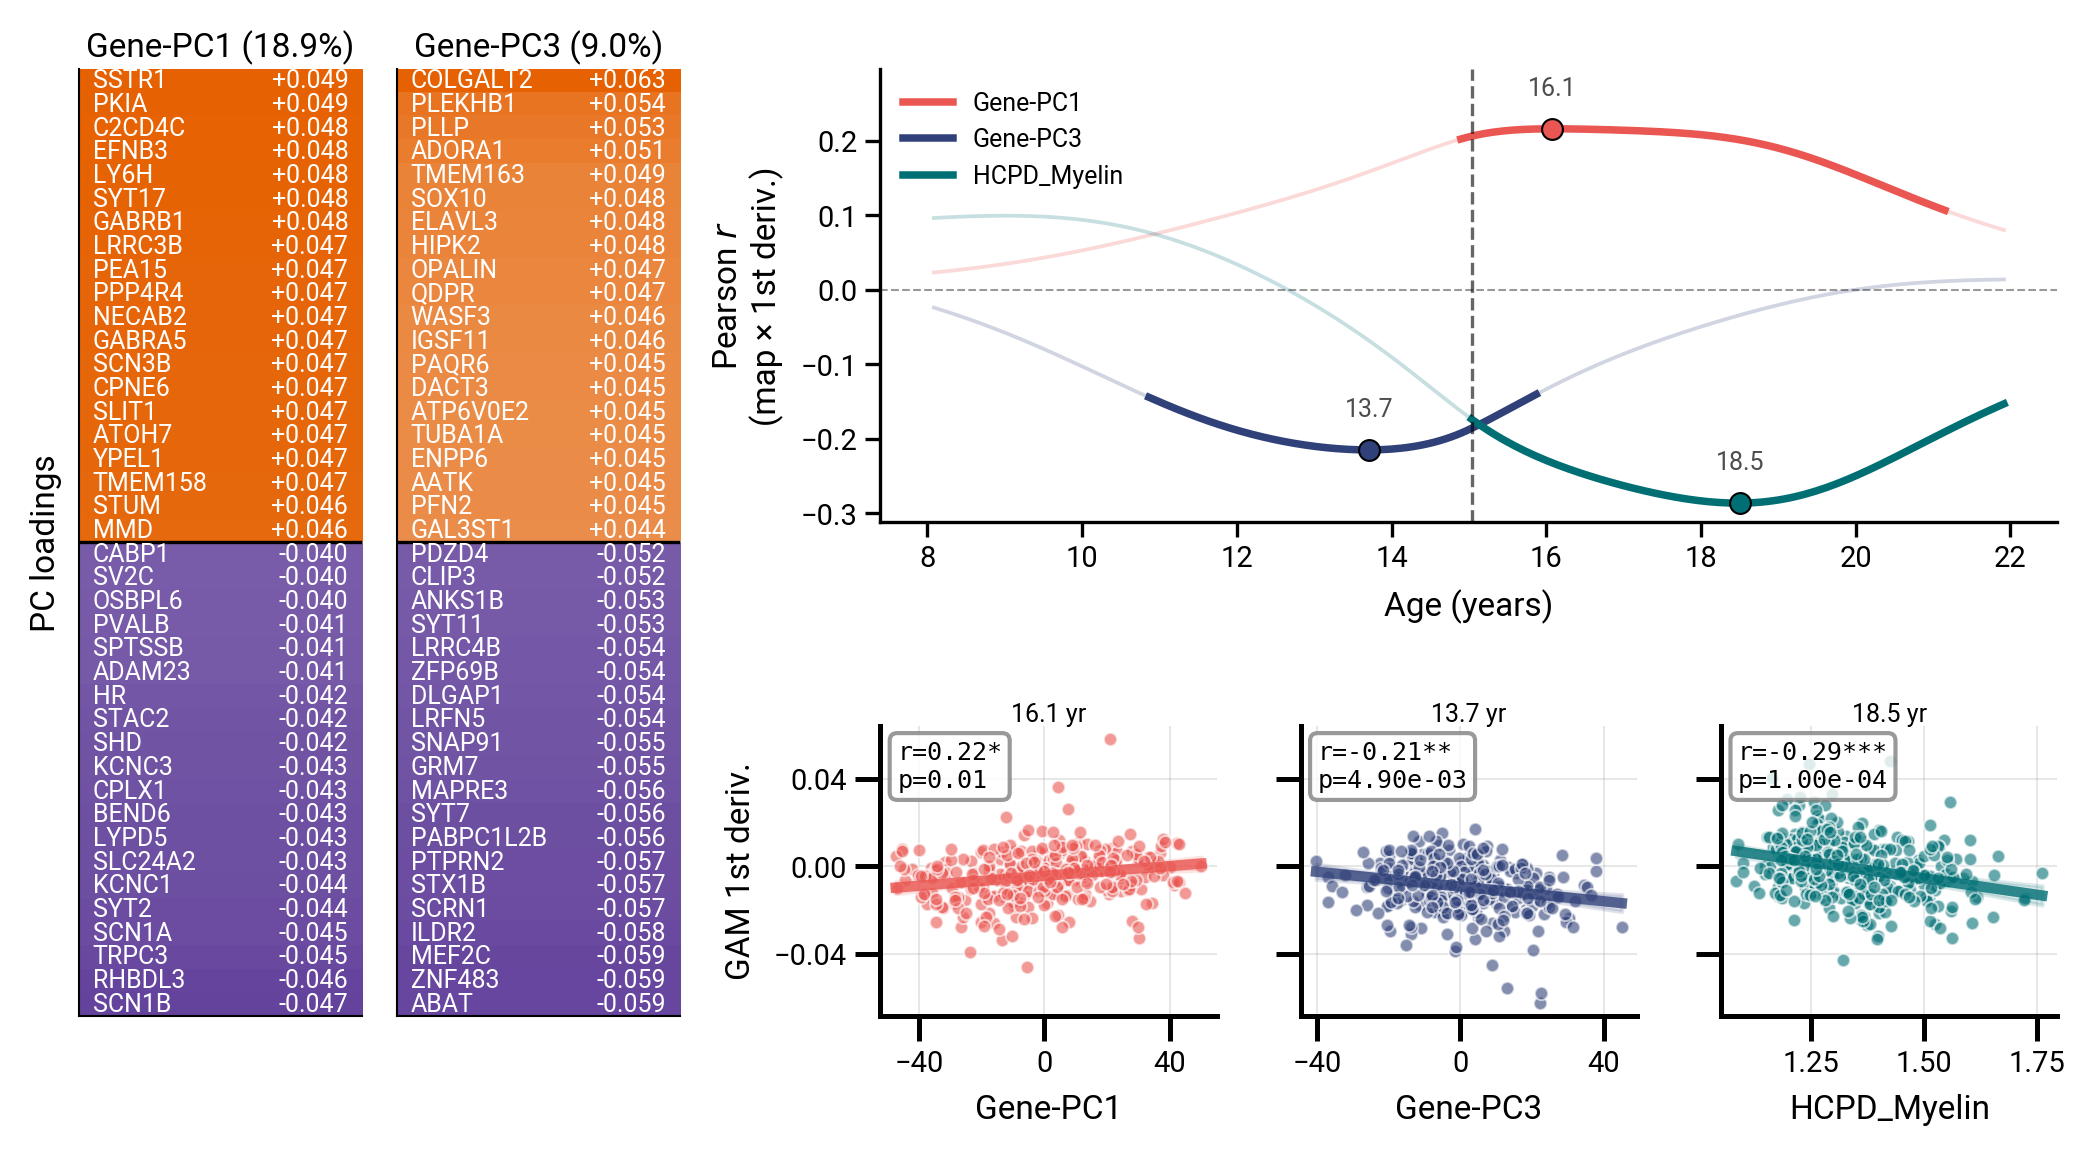


PC x reference-map correlations (pearson, 10000 BrainSMASH surrogates of each reference; * = p < 0.05. p is floored at 1/N_PERMS = 0.0001, the finest a permutation test at this count can resolve).
            var    n        HCPD_Myelin            SA_Axis
Gene-PC1  18.9%  347  -0.722 (p=0.000)*  +0.678 (p=0.000)*
Gene-PC3   9.0%  347   +0.052 (p=0.547)   -0.108 (p=0.213)
  table -> fig4_neurobio-pc_d1_Genes-Myelin_tfMRICARITPA_deflection_abs_demean_restlen-CARIT_gao_refcorr.csv


In [9]:
# ── Panel sets 3 + 4 combined: PC loadings (left) + developmental coupling (right) ───────────────
# One figure, read from the compute cells above: PC loadings at each pole (left) beside each map's coupling to
# the GAM derivative across age (right).

# ---- coupling block (right) ----
SHOW_SCATTER_ROW = True

if SHOW_SCATTER_ROW:
    PANEL_FAMILY     = ['Genes', 'Myelin']
    PANEL_WIDTH      = 1.5          # width of one coupling column (inches
    ROW_HEIGHTS      = (2.5, 1.6)
else:
    PANEL_FAMILY     = ['Genes']
    PANEL_WIDTH      = 1          # width of one coupling column (inches)
    ROW_HEIGHTS      = (4, 0)
DERIV_ORDER_SHOW = 1            # 1 = rate of change, 2 = acceleration
ALPHA_SIG        = 0.05
SIG_ONLY         = False
MIN_SIG_RUN      = 1
PANEL_PALETTE    = 'snap_trio'  # 'snap_trio' = the lab's three categorical colours (raspberry
                                # blush / starry-night blue / north-sea green), for <= 3 maps;
                                # 'viridis' = the sequential ramp, for any number of maps.

ZOOM_SHARE_Y     = True         # row 2 shares one y-axis (False = per-panel axes)
GS_SPACING       = dict(hspace=0.55, wspace=0.25)   # within the coupling block
TICK_MAX         = dict(x=3, y=4)                   # max ticks per row-2 axis (narrow panels)

# ---- PC loading block (left) ----
PC_TOP_N         = 20                # genes shown per pole (so 2 x PC_TOP_N cells per PC)
# Width of one PC column (inches), wide enough for the longest gene symbol and its value.
if SHOW_SCATTER_ROW:
    PC_PANEL_WIDTH   = 1.15
else:
    PC_PANEL_WIDTH   = 1.1
# PC_HEATMAP_CMAP  = 'snap_blue_pink'  # diverging map, centred on zero
PC_HEATMAP_CMAP  = 'snap_purple_orange'  # diverging map, centred on zero
PC_CELL_FONTSIZE = 6                 # in-cell gene name / loading text
PC_ALPHA_SIG     = 0.05              # * threshold in the reference-map table

# ---- how the two blocks sit together ----
# The block gap clears the coupling block's interior y-labels, and the PC block needs no left margin.
if SHOW_SCATTER_ROW:
    BLOCK_WSPACE     = 0.225         # gap between the two blocks (fraction of a block width)
else:
    BLOCK_WSPACE     = 0.15         # gap between the two blocks (fraction of a block width)
FIG_MARGINS      = dict(left=0.02, right=0.99, top=0.90, bottom=0.13)

if DERIV_ORDER_SHOW not in DERIV_ORDERS:
    raise ValueError(f'DERIV_ORDER_SHOW={DERIV_ORDER_SHOW} is not in DERIV_ORDERS={DERIV_ORDERS}; '
                     'add it there and re-run the neurobiology compute cell.')
# One name or several: normalise to a list once, here, so everything below is family-agnostic.
# dict.fromkeys de-duplicates while keeping the order the families were named in.
PANEL_FAMILIES = ([PANEL_FAMILY] if isinstance(PANEL_FAMILY, str)
                  else list(dict.fromkeys(PANEL_FAMILY)))
if not PANEL_FAMILIES:
    raise ValueError('PANEL_FAMILY is empty; name at least one family.')
_unknown = [f for f in PANEL_FAMILIES if f not in neuro_families]
if _unknown:
    raise KeyError(f'PANEL_FAMILY entries {_unknown} are not computed families: '
                   f'{list(neuro_families)}')
if PC_TOP_N >= PC_STABILITY_WINDOW:
    raise ValueError(f'PC_TOP_N ({PC_TOP_N}) must be below PC_STABILITY_WINDOW '
                     f'({PC_STABILITY_WINDOW}), otherwise the stable pool cannot fill the panel. '
                     'Raise the window in the PC compute cell and re-run it.')
if set(neuro_families) - set(PANEL_FAMILIES):
    print(f'Computed but not plotted: {sorted(set(neuro_families) - set(PANEL_FAMILIES))}')

# Traces are keyed by (family, column), which stays unique when several families are plotted.
_traces = [(fam, col) for fam in PANEL_FAMILIES for col in neuro_families[fam].columns]
_key    = lambda fc: f'd{DERIV_ORDER_SHOW}|{fc[0]}::{fc[1]}'
# Display names qualify a map with its family only where the name repeats, fixed before any SIG_ONLY
# filtering.
_dupes  = {col for _, col in _traces if sum(col == c for _, c in _traces) > 1}
_label  = {fc: (f'{fc[0]}::{fc[1]}' if fc[1] in _dupes else fc[1]) for fc in _traces}
_fam_stem = '-'.join(PANEL_FAMILIES)        # panel filename component; '-' joins, as in 'Genes-Myelin'
if SIG_ONLY:
    _keep = [fc for fc in _traces if longest_sig_run(r_pval[_key(fc)], ALPHA_SIG) >= MIN_SIG_RUN]
    _drop = [_label[fc] for fc in _traces if fc not in _keep]
    print(f'{_fam_stem}: keeping {len(_keep)}/{len(_traces)} maps with a significant section '
          f'(>= {MIN_SIG_RUN} consecutive points)' + (f'; dropped {_drop}' if _drop else ''))
    _traces = _keep
if not _traces:
    raise ValueError(f'No maps left to plot for {PANEL_FAMILIES} (SIG_ONLY dropped them all).')

# One colour per trace, shared by its row-1 line and row-2 scatter and assigned by position.
_snap_trio = get_snap_colors(cat_trio=False, as_list=True)      # categorical, distinguishable
if PANEL_PALETTE == 'snap_trio' and len(_traces) <= len(_snap_trio):
    _colors = _snap_trio[:len(_traces)]
    # _colors = [_snap_trio['north_sea_green'],_snap_trio['wenge']]
else:
    if PANEL_PALETTE == 'snap_trio':
        print(f'PANEL_PALETTE={PANEL_PALETTE!r} carries {len(_snap_trio)} colours but '
              f'{len(_traces)} maps are plotted; falling back to viridis.')
    _colors = plt.cm.viridis(np.linspace(0.0, 0.9, len(_traces)))
_ord_label = {1: '1st', 2: '2nd'}
_deriv     = grid_derivatives(sig_pred, age_grid, DERIV_ORDER_SHOW)      # (n_regions, n_grid)
# Mark each trace at its strongest coupling among the significant ages only (None when no age reaches
# ALPHA_SIG).
def _sig_peak(fc):
    r, p = r_point[_key(fc)], np.asarray(r_pval[_key(fc)], dtype=float)
    ok   = np.isfinite(r) & (p < ALPHA_SIG)          # NaN p compares False, so it cannot be picked
    return int(np.nanargmax(np.where(ok, np.abs(r), np.nan))) if ok.any() else None

_peak    = {fc: _sig_peak(fc) for fc in _traces}     # age index per map, or None
_unmarked = [_label[fc] for fc in _traces if _peak[fc] is None]
if _unmarked:
    print(f'No age reaches p < {ALPHA_SIG:g} for {_unmarked}; those traces are drawn faded, with no '
          'marker, no age label and an empty row-2 panel (set SIG_ONLY = True to drop them).')

# Colour the PC titles like their traces only when both blocks show the same components in the same order.
_plotted = [_label[fc] for fc in _traces]
_linked  = _plotted == pc_names
if not _linked:
    print(f'NOTE: the coupling block shows {_plotted} but the PC block shows {pc_names}; titles are '
          'left black rather than implying a colour correspondence that does not hold.')

# ── Figure: [ left: one loading column per PC ] [ right: traces (over scatters) ] ──
# The coupling block is one row or two, so the figure height follows the rows actually drawn and a
# hidden scatter row leaves no gap behind it.
_row_h      = list(ROW_HEIGHTS) if SHOW_SCATTER_ROW else [ROW_HEIGHTS[0]]
_pc_w       = PC_PANEL_WIDTH * len(pc_names)
_coupling_w = PANEL_WIDTH * len(_traces)
fig = plt.figure(figsize=(_pc_w + _coupling_w, sum(_row_h)), dpi=300)
gs_outer    = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[_pc_w, _coupling_w],
                                wspace=BLOCK_WSPACE, **FIG_MARGINS)
gs_pc       = gridspec.GridSpecFromSubplotSpec(1, len(pc_names), subplot_spec=gs_outer[0],
                                               wspace=0.12)
gs_coupling = gridspec.GridSpecFromSubplotSpec(len(_row_h), len(_traces), subplot_spec=gs_outer[1],
                                               height_ratios=_row_h, **GS_SPACING)

# ── Right row 1: coupling traces, with a marker at the age each row-2 panel zooms into ──
ax = fig.add_subplot(gs_coupling[0, :])
for color, fc in zip(_colors, _traces):
    r, p, i = r_point[_key(fc)], r_pval[_key(fc)], _peak[fc]
    ax.plot(age_grid, r, color=color, lw=0.9, alpha=0.22)                 # full trace, faded
    ax.plot(age_grid, np.where(p < ALPHA_SIG, r, np.nan),                 # bold where significant
            color=color, lw=1.8, alpha=1.0, label=_label[fc])
    if i is not None:
        ax.plot(age_grid[i], r[i], marker='o', color=color, mec='k', mew=0.5, ms=5, zorder=5)

# Age labels sit above their markers, staggered only when another label is close in both age and r.
ax.set_ylim(top=ax.get_ylim()[1] + 0.10 * np.ptp(ax.get_ylim()))
_x_gap = 0.10 * np.ptp(age_grid)
_y_gap = 0.15 * np.ptp(ax.get_ylim())
_placed = {}                                    # level -> [(age, r) already labelled at that level]
for fc in sorted([t for t in _traces if _peak[t] is not None], key=lambda t: age_grid[_peak[t]]):
    i, r = _peak[fc], r_point[_key(fc)]
    _x, _y, _lvl = age_grid[i], r[i], 0
    while any(abs(_x - px) < _x_gap and abs(_y - py) < _y_gap for px, py in _placed.get(_lvl, [])):
        _lvl += 1
    _placed.setdefault(_lvl, []).append((_x, _y))
    ax.annotate(f'{_x:.1f}', (_x, _y), textcoords='offset points', xytext=(0, 8 + 10 * _lvl),
                ha='center', fontsize=6, color='0.3')
ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
# The single stage boundary in use here. fig3 can draw several dashed lines when its n_bkps > 1,
# but those extra change points are annotation-only there and never define a stage.
ax.axvline(inflection_age, color='k', lw=0.8, ls='--', alpha=0.6)
ax.set_xlabel('Age (years)', fontsize=8)
ax.set_ylabel(f'Pearson $r$\n(map × {_ord_label[DERIV_ORDER_SHOW]} deriv.)', fontsize=8)
ax.tick_params(labelsize=7, pad=2)
ax.legend(fontsize=6, frameon=False, loc='best', ncol=1)

# ── Right row 2: the scatter behind each marker ──
# The loop runs whether or not the row is drawn: only the AXES are conditional, so hiding the row
# costs nothing from the console report below (peak age, r, p_smash, parcel count per map).
_axz0 = None
for j, (color, fc) in enumerate(zip(_colors, _traces)):
    fam, col = fc
    i    = _peak[fc]
    if i is None:
        # No significant age: keep an empty, unshared panel so the columns stay aligned with their traces.
        if SHOW_SCATTER_ROW:
            axz = fig.add_subplot(gs_coupling[1, j])
            axz.set_xticks([])
            axz.set_yticks([])
            for _sp in axz.spines.values():
                _sp.set_linewidth(0.5)
            axz.text(0.5, 0.5, f'no p < {ALPHA_SIG:g}', transform=axz.transAxes, ha='center',
                     va='center', fontsize=6, color='0.5')
            axz.set_title(_label[fc], fontsize=6, pad=0)
        print(f'  {_label[fc]}: no age reaches p < {ALPHA_SIG:g} '
              f'(strongest |r| overall {np.nanmax(np.abs(r_point[_key(fc)])):.3f} at '
              f'{age_grid[int(np.nanargmax(np.abs(r_point[_key(fc)])))]:.1f} yr, n.s.)'
              + ('; panel left empty' if SHOW_SCATTER_ROW else ''))
        continue
    # The scatter uses the same hemisphere-restricted parcels as r_point and r_pval.
    _map = restrict_hemi(neuro_families[fam][col].astype(float).values)
    _y   = _deriv[:, i]
    _fin = np.isfinite(_map) & np.isfinite(_y)
    if SHOW_SCATTER_ROW:
        axz   = fig.add_subplot(gs_coupling[1, j], sharey=_axz0 if ZOOM_SHARE_Y else None)
        _axz0 = _axz0 or axz
        plot_correlation(pd.Series(_map[_fin]), pd.Series(_y[_fin]), axz, x_label=_label[fc],
                         color=color,
                         y_label=f'GAM {_ord_label[DERIV_ORDER_SHOW]} deriv.', method='pearson',
                         show_stats=True, fontsize=8,
                         custom_pvalue=max(r_pval[_key(fc)][i], 1 / N_PERMS))
        if axz is not _axz0:    # the first DRAWN panel keeps the label -- keying on j would lose it
                                # whenever column 0 is one of the empty, non-significant panels
            axz.set_ylabel('')      # plot_correlation fills a blank label, so clear it after
            if ZOOM_SHARE_Y:
                axz.tick_params(labelleft=False)   # shared scale -> inner tick labels are redundant,
                                                   # and at this width they overran the panel left
        axz.set_title(f'{age_grid[i]:.1f} yr', fontsize=6, pad=0)
        axz.xaxis.set_major_locator(plt.MaxNLocator(TICK_MAX['x']))
        axz.yaxis.set_major_locator(plt.MaxNLocator(TICK_MAX['y']))
        axz.tick_params(labelsize=7, pad=2)
    print(f'  {_label[fc]}: strongest significant coupling at {age_grid[i]:.1f} yr -- '
          f'r={r_point[_key(fc)][i]:+.3f}, '
          f'p_smash={max(r_pval[_key(fc)][i], 1 / N_PERMS):.4f}'
          + ('*' if r_pval[_key(fc)][i] < ALPHA_SIG else '') + f', n={int(_fin.sum())} parcels')

# ── Left block: one loading column per PC ──
_cmap = plt.get_cmap(PC_HEATMAP_CMAP)
for j, (pc, idx) in enumerate(zip(pc_names, pc_idx)):
    axp = fig.add_subplot(gs_pc[0, j])
    w   = pc_loadings[:, idx]
    # Keep the first PC_TOP_N genes at each pole that pass that pole's stability threshold.
    _rank_neg = np.argsort(w)                                       # most negative first
    _rank_pos = _rank_neg[::-1]                                     # most positive first
    _sel_neg  = [i for i in _rank_neg if pc_neg_freq[i, idx] >= PC_MIN_STABILITY][:PC_TOP_N]
    _sel_pos  = [i for i in _rank_pos if pc_pos_freq[i, idx] >= PC_MIN_STABILITY][:PC_TOP_N]
    rows = ([(i, pc_neg_freq[i, idx]) for i in _sel_neg]            # bottom: most negative
            + [(i, pc_pos_freq[i, idx]) for i in _sel_pos[::-1]])   # top: most positive
    _n_neg = len(_sel_neg)
    _vals  = [w[i] for i, _ in rows]
    _names = [pc_features[i] for i, _ in rows]

    # Colour limits come from the full loading vector, so colour shows the pole and the printed value the
    # magnitude.
    _vmax = float(np.nanmax(np.abs(w)))
    _norm = plt.Normalize(vmin=-_vmax, vmax=_vmax)
    axp.imshow(np.asarray(_vals)[:, None], cmap=_cmap, norm=_norm, aspect='auto', origin='lower',
               extent=[-0.5, 0.5, -0.5, len(rows) - 0.5], interpolation='nearest')
    for p, (v, nm) in enumerate(zip(_vals, _names)):
        # Ink colour follows the cell it sits on, so saturated poles stay readable.
        _r, _g, _b, _ = _cmap(_norm(v))
        # _ink = 'k' if (0.299 * _r + 0.587 * _g + 0.114 * _b) > 0.55 else 'w'
        _ink = 'w'
        axp.text(-0.45, p, nm, ha='left', va='center', fontsize=PC_CELL_FONTSIZE, color=_ink)
        axp.text(0.45, p, f'{v:+.3f}', ha='right', va='center', fontsize=PC_CELL_FONTSIZE,
                 color=_ink)
    if 0 < _n_neg < len(rows):
        axp.axhline(_n_neg - 0.5, color='k', lw=0.8)                # divider between the two poles
    axp.set_xticks([])
    axp.set_yticks([])
    axp.set_xlim(-0.5, 0.5)
    axp.set_ylim(-0.5, len(rows) - 0.5)
    for _sp in axp.spines.values():
        _sp.set_linewidth(0.5)
    if j == 0:
        axp.set_ylabel('PC loadings', fontsize=8)
    axp.set_title(f'{pc} ({pc_evr[idx]:.1%})', fontsize=8, pad=3,
                #   color='k')
                  color=_colors[j] if _linked else 'k')

    _st = np.array([st for _, st in rows])
    print(f'  {pc}: {len(rows)} genes shown ({_n_neg} negative pole, {len(rows) - _n_neg} positive); '
          f'stability median {np.median(_st):.0%}, range {_st.min():.0%}-{_st.max():.0%}')
    if PC_MIN_STABILITY > 0:
        # Report what the filter changed, so a hidden or promoted gene is never a silent edit.
        _raw  = list(_rank_neg[:PC_TOP_N]) + list(_rank_pos[:PC_TOP_N])
        _kept = set(_sel_neg) | set(_sel_pos)
        _hid  = [str(pc_features[i]) for i in _raw if i not in _kept]
        _new  = [str(pc_features[i]) for i in _sel_neg + _sel_pos if i not in set(_raw)]
        _pool = (int((pc_neg_freq[:, idx] >= PC_MIN_STABILITY).sum()),
                 int((pc_pos_freq[:, idx] >= PC_MIN_STABILITY).sum()))
        print(f'    stable pool: {_pool[0]} neg / {_pool[1]} pos genes clear '
              f'{PC_MIN_STABILITY:.0%} within the top {PC_STABILITY_WINDOW}')
        if len(_sel_neg) < PC_TOP_N or len(_sel_pos) < PC_TOP_N:
            print(f'    NOTE: pool smaller than PC_TOP_N={PC_TOP_N} at one or both poles '
                  f'({len(_sel_neg)} neg, {len(_sel_pos)} pos shown) -- raise PC_STABILITY_WINDOW '
                  f'or lower PC_MIN_STABILITY for equal-length panels.')
        print(f'    hidden (in the raw top-{PC_TOP_N} but unstable): {_hid or "none"}')
        print(f'    promoted (stable, from below the top-{PC_TOP_N}): {_new or "none"}')

# No tight_layout, which would undo the explicit spacing, and gene-panel figures carry gene_tag so 'gao' and
# 'dear' never overwrite each other.
_fam_tag = gene_tag if 'Genes' in PANEL_FAMILIES else ''
_path = save_panel(fig, fig_dir, f'fig4_neurobio-pc_d{DERIV_ORDER_SHOW}_{_fam_stem}_{task_scan}'
                        f'_{signal_type}{variant_tag}{_fam_tag}')
print(f'{_fam_stem}: {len(_traces)} maps + {len(pc_names)} PC loading columns '
      f'-> {os.path.basename(_path)}.{{png,svg}}')
plt.show()

# ── PC x reference-map correlations (reported, not plotted) ──
_csv = f'{_path}_refcorr.csv'
pc_ref_table.to_csv(_csv)
print(f'\nPC x reference-map correlations ({PC_CORR_METHOD}, {N_PERMS} BrainSMASH surrogates of each '
      f'reference; * = p < {PC_ALPHA_SIG}. p is floored at 1/N_PERMS = {1 / N_PERMS:g}, the finest '
      f'a permutation test at this count can resolve).')
_fmt = pd.DataFrame({'var': pc_ref_table['var_explained'].map('{:.1%}'.format),
                     'n':   pc_ref_table['n_parcels']})
for _m in PC_REF_MAPS:
    _fmt[_m] = [f'{r:+.3f} (p={p:.3f})' + ('*' if p < PC_ALPHA_SIG else '')
                for r, p in zip(pc_ref_table[f'{_m}_r'], pc_ref_table[f'{_m}_p'])]
print(_fmt.to_string())
print(f'  table -> {os.path.basename(_csv)}')

## Reference maps on the surface

Gene-PC1 (Genes): 347/400 parcels, colour range [-1.9, +1.9] (z-scored) -> fig4_refmap_Gene-PC1_gao.{png,svg}


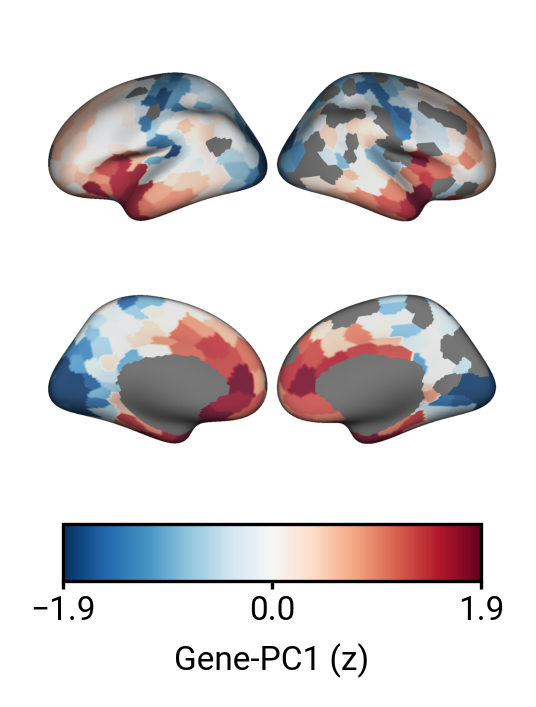

Gene-PC3 (Genes): 347/400 parcels, colour range [-2, +2] (z-scored) -> fig4_refmap_Gene-PC3_gao.{png,svg}


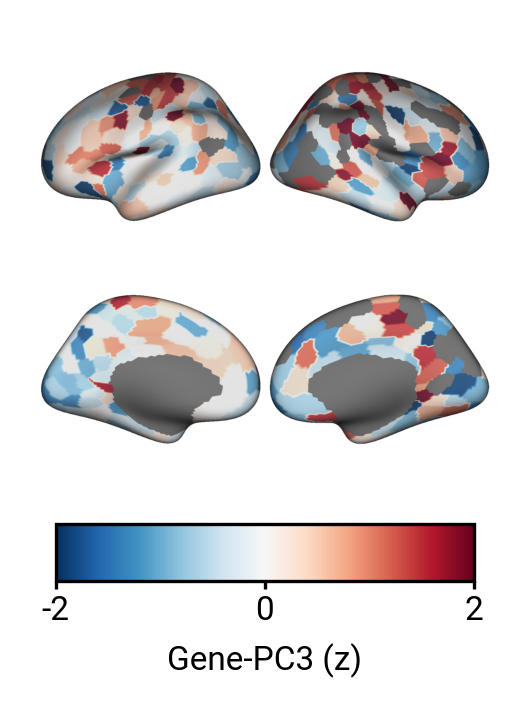

HCPD_Myelin (Myelin): 400/400 parcels, colour range [-1.9, +1.9] (z-scored) -> fig4_refmap_HCPD_Myelin.{png,svg}


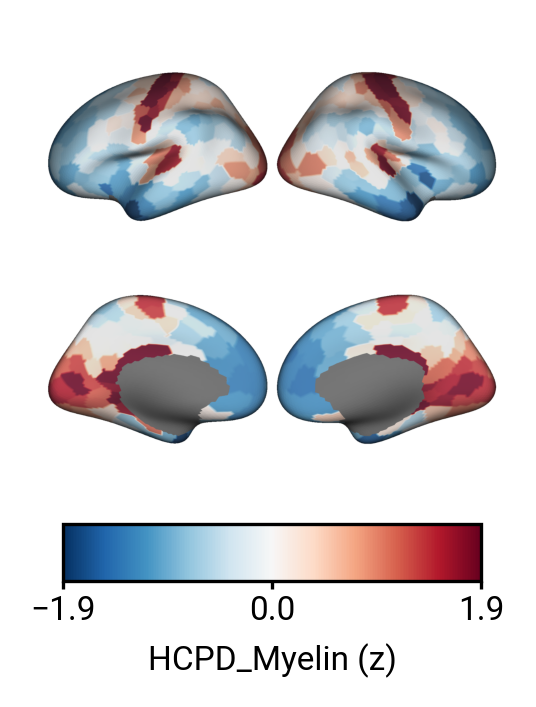

In [10]:
# ── Panel set 5: the reference maps themselves, one standalone surface figure per map ───────────
MAP_SURF_FIGSIZE     = (2.25, 2.5)   # matches fig3's stage-map surfaces, so the two sit together
MAP_SURF_CMAP        = 'RdBu_r'      # diverging; with MAP_SURF_STANDARDIZE it is centred on 0
MAP_SURF_STANDARDIZE = True          # z-score each map over its parcels (False = raw values, 2.5-97.5 percentile range)
MAP_SURF_PCT         = 95            # colour limit percentile of |z|, so one extreme parcel cannot
                                     # flatten the rest of the map
MAP_SURF_MAPS        = None          # None = every family map, or a list of names (any fitted gene PC allowed)

# The pool of drawable maps: what the families contribute, plus every fitted gene PC. setdefault
# keeps the family version where a name is in both, so a map is never drawn from two sources.
_surf_pool = {col: (fam, df[col].astype(float).values)
              for fam, df in neuro_families.items() for col in df.columns}
if df_genes is not None:
    for _nm in gene_catalog_pcs:
        _surf_pool.setdefault(_nm, ('Genes', gene_catalog[_nm][1]))

_surf_names = ([col for df in neuro_families.values() for col in df.columns]
               if MAP_SURF_MAPS is None else list(dict.fromkeys(MAP_SURF_MAPS)))
_unknown_surf = [m for m in _surf_names if m not in _surf_pool]
if _unknown_surf:
    raise KeyError(f'MAP_SURF_MAPS: unknown map name(s) {_unknown_surf}.\nAvailable:\n  '
                   + '\n  '.join(sorted(_surf_pool)))

for _nm in _surf_names:
    _fam, _vals = _surf_pool[_nm]
    _vals = restrict_hemi(np.asarray(_vals, dtype=float))
    if MAP_SURF_STANDARDIZE:
        # z over the parcels that HAVE data, so a coverage difference between maps does not shift
        # the centre and the colour limit means the same thing on every panel.
        _vals = (_vals - np.nanmean(_vals)) / np.nanstd(_vals)
        # Rounded to one decimal so the colourbar's end ticks read cleanly.
        _lim  = float(np.nanpercentile(np.abs(_vals), MAP_SURF_PCT))
        _lim  = round(_lim, 1) or _lim
        _vmin, _vmax, _cblab = -_lim, _lim, f'{_nm} (z)'
    else:
        _vmin, _vmax = (round(float(v), 2) for v in np.nanpercentile(_vals, [2.5, 97.5]))
        _cblab = _nm

    fig = plt.figure(figsize=MAP_SURF_FIGSIZE, dpi=300)
    plot_brain_surface_data_single(_vals, fig, gridspec.GridSpec(1, 1, figure=fig)[0, 0],
                                   parcellation=f'schaefer_{n_regions}-7', cmap=MAP_SURF_CMAP,
                                   vmin=_vmin, vmax=_vmax,
                                   symmetric_cbar=bool(MAP_SURF_STANDARDIZE),
                                   cbar_label=_cblab, fontsize=8)
    # File stems follow the null-cache tagging rule and omit task and signal tags, since a reference map does
    # not depend on the GAM.
    _tag  = (gene_tag if _nm in _panel_dep else '') + hemi_tag
    _path = save_panel(fig, fig_dir, f'fig4_refmap_{_nm.replace(" ", "_")}{_tag}')
    print(f'{_nm} ({_fam}): {int(np.isfinite(_vals).sum())}/{n_regions} parcels, colour range '
          f'[{_vmin:+.3g}, {_vmax:+.3g}]'
          + (' (z-scored)' if MAP_SURF_STANDARDIZE else ' (raw values)')
          + f' -> {os.path.basename(_path)}.{{png,svg}}')
    plt.show()